# Assignment 2 — Question 2: Sampling and bootstrap

**Population:** all 768 records in `data_raw/diabetes.csv`

**Reproducible seed:** 42.  

**Sample:** 25 records without replacement for parts (a)–(b).  

**Bootstrap:** 500 independent resamples of 150 rows **with replacement** from the full population for part (c).

**Percentile choice in (c):** the 98th percentile, to match part (b), because the question does not specify which percentile.

Population summaries treat the dataset as the entire population, and therefore population standard deviation uses `ddof=0`. Each resample's standard deviation uses `ddof=1`, the usual sample statistic. Zeros in `Glucose`, `BloodPressure`, and `BMI` are kept **exactly as supplied**; some may represent unavailable clinical measures, but replacing them would change the defined assignment population and was not requested.

In [ ]:
# ============================================================
# 1. Import Required Python Libraries
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ============================================================
# 2. Identify the Project Root Directory
# ============================================================

# Determine whether the notebook is running from the
# project root or from the src subdirectory.
current_directory = Path.cwd()

if (current_directory / "data_raw" / "diabetes.csv").is_file():
    ROOT = current_directory

elif (current_directory.parent / "data_raw" / "diabetes.csv").is_file():
    ROOT = current_directory.parent

else:
    raise FileNotFoundError(
        "Unable to locate data_raw/diabetes.csv. "
        "Run the notebook from the project root or src folder."
    )


# ============================================================
# 3. Load the Diabetes Dataset
# ============================================================

# Define the location of the original diabetes dataset.
dataset_path = ROOT / "data_raw" / "diabetes.csv"

# Load the dataset into a pandas DataFrame.
population = pd.read_csv(dataset_path)


# ============================================================
# 4. Define the Expected Dataset Attributes
# ============================================================

# Specify the eight predictor variables and
# the binary diabetes outcome variable.
expected_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]


# ============================================================
# 5. Validate Dataset Structure
# ============================================================

# Confirm that all required columns are present.
missing_columns = set(expected_columns) - set(
    population.columns
)

assert not missing_columns, (
    f"Required dataset columns are missing: {missing_columns}"
)

# Confirm that the population contains 768 observations.
expected_population_size = 768

assert len(population) == expected_population_size, (
    "Population size does not match the expected 768 records."
)

# Confirm that the response variable is binary.
assert population["Outcome"].isin([0, 1]).all(), (
    "Outcome contains values other than 0 and 1."
)


# ============================================================
# 6. Initialize the Random Number Generator
# ============================================================

# Define a fixed random seed to ensure reproducibility.
SEED = 42

# Initialize the NumPy random number generator.
# The same seed produces the same random sequence
# when notebook cells are executed in the same order.
rng = np.random.default_rng(SEED)


# ============================================================
# 7. Examine Missing Values
# ============================================================

# Calculate the number of missing values in each column.
missing_values = population.isna().sum()

# Create a summary table for missing-value inspection.
missing_values_summary = missing_values.to_frame(
    name="Missing_Count"
)

print("Missing Values by Column:")

display(missing_values_summary)


# ============================================================
# 8. Display Dataset Information
# ============================================================

# Report the dataset location and dimensions.
print("\nDIABETES DATASET INFORMATION")
print("-" * 60)

print(f"Dataset: {dataset_path.relative_to(ROOT)}")
print(f"Population Size: {len(population):,}")
print(f"Number of Columns: {len(population.columns)}")
print(f"Random Seed: {SEED}")

# Display the first five observations.
print("\nPreview of Diabetes Dataset:")

display(population.head())

print("\nDataset initialization and validation completed.")


Missing Values by Column:


,Missing_Count
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



DIABETES DATASET INFORMATION
------------------------------------------------------------
Dataset: data_raw/diabetes.csv
Population Size: 768
Number of Columns: 9
Random Seed: 42

Preview of Diabetes Dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset initialization and validation completed.


## (a) Random sample of 25: mean and highest Glucose

Sample without replacement using a seeded random generator. Compare the sample's mean and maximum to corresponding full-population values. The maximum is strongly sample-size dependent, so a lower sample maximum is not evidence of a different underlying population.

Glucose Statistics: Sample vs. Population


,Statistic,Sample (n=25),Population (N=768)
0,Mean Glucose,113.44,120.895
1,Maximum Glucose,179.00,199.000


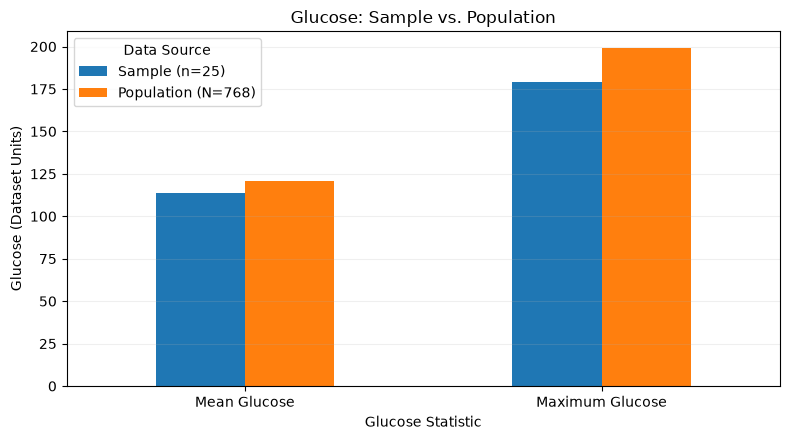


Sample vs. Population Differences
Mean Glucose Difference: -7.45
Maximum Glucose Difference: -20

All glucose sampling and validation checks passed.


In [12]:
# ============================================================
# 1. Generate a Random Sample
# ============================================================

# Randomly select 25 observations from the population.
# Sampling without replacement ensures that each
# observation can only be selected once.
sample_size = 25

sample_indices = rng.choice(
    len(population),
    size=sample_size,
    replace=False
)

# Create a separate DataFrame containing the sample.
sample = population.iloc[sample_indices].copy()


# ============================================================
# 2. Calculate Sample and Population Glucose Statistics
# ============================================================

# Calculate the mean and maximum glucose values
# for the randomly selected sample.
sample_mean_glucose = sample["Glucose"].mean()
sample_max_glucose = sample["Glucose"].max()

# Calculate the corresponding population statistics.
population_mean_glucose = population["Glucose"].mean()
population_max_glucose = population["Glucose"].max()


# ============================================================
# 3. Create a Statistical Comparison Table
# ============================================================

# Organize the sample and population statistics
# into a DataFrame for comparison.
glucose_metrics = pd.DataFrame({
    "Statistic": [
        "Mean Glucose",
        "Maximum Glucose"
    ],
    "Sample (n=25)": [
        sample_mean_glucose,
        sample_max_glucose
    ],
    "Population (N=768)": [
        population_mean_glucose,
        population_max_glucose
    ]
})

# Display the comparison table.
print("Glucose Statistics: Sample vs. Population")

display(
    glucose_metrics.round(3)
)


# ============================================================
# 4. Visualize Sample and Population Glucose Statistics
# ============================================================

# Create a grouped bar chart comparing the mean
# and maximum glucose values.
ax = (
    glucose_metrics
    .set_index("Statistic")[
        [
            "Sample (n=25)",
            "Population (N=768)"
        ]
    ]
    .plot.bar(
        figsize=(8, 4.5),
        rot=0
    )
)

# Configure the chart title and axis labels.
ax.set(
    title="Glucose: Sample vs. Population",
    xlabel="Glucose Statistic",
    ylabel="Glucose (Dataset Units)"
)

# Add a legend and horizontal gridlines.
ax.legend(title="Data Source")

ax.grid(
    axis="y",
    alpha=0.2
)

# Adjust spacing and display the chart.
plt.tight_layout()
plt.show()


# ============================================================
# 5. Calculate Differences Between Sample and Population
# ============================================================

# Calculate how much the sample statistics differ
# from the corresponding population statistics.
mean_glucose_difference = (
    sample_mean_glucose - population_mean_glucose
)

max_glucose_difference = (
    sample_max_glucose - population_max_glucose
)

# Display the differences.
print("\nSample vs. Population Differences")

print(
    f"Mean Glucose Difference: "
    f"{mean_glucose_difference:+.2f}"
)

print(
    f"Maximum Glucose Difference: "
    f"{max_glucose_difference:+.0f}"
)


# ============================================================
# 6. Validate Sampling and Statistical Results
# ============================================================

# Confirm that the sample contains exactly 25 observations.
assert len(sample) == sample_size, (
    "The sample size does not match the required 25 observations."
)

# Confirm that sampling occurred without replacement.
assert len(set(sample_indices)) == sample_size, (
    "Duplicate observations were selected."
)

# Confirm that the sample maximum does not exceed
# the population maximum.
assert sample_max_glucose <= population_max_glucose, (
    "Sample maximum exceeds the population maximum."
)

# Confirm that all calculated glucose metrics are valid.
assert glucose_metrics.iloc[:, 1:].notna().all().all(), (
    "Missing values detected in the glucose statistics."
)

print("\nAll glucose sampling and validation checks passed.")


## (b) 98th percentile of BMI

`numpy.percentile` uses linear interpolation by default. The same calculation is applied to sample and population.

BMI 98th Percentile: Sample vs. Population


,Group,BMI_98th_percentile
0,Sample (n=25),42.516
1,Population (N=768),47.526


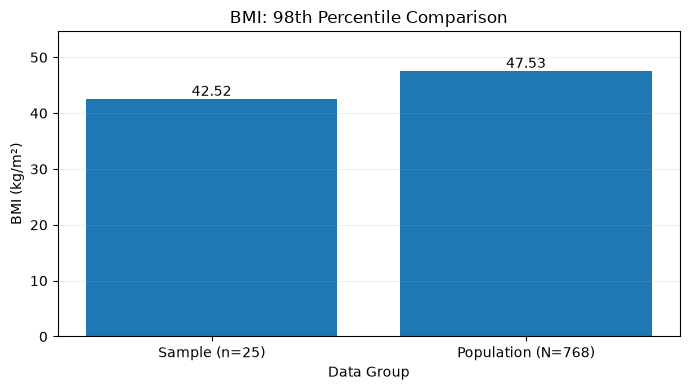


BMI Percentile Comparison Results
Sample 98th Percentile: 42.52
Population 98th Percentile: 47.53
Difference (Sample - Population): -5.01 BMI units

All BMI percentile validation checks passed.


In [13]:
# ============================================================
# 1. Define the Percentile for Analysis
# ============================================================

# Specify the percentile used to compare BMI values
# between the random sample and the full population.
percentile_level = 98


# ============================================================
# 2. Calculate Sample and Population BMI Percentiles
# ============================================================

# Calculate the 98th percentile of BMI for the
# randomly selected sample of 25 observations.
bmi_sample = np.percentile(
    sample["BMI"],
    percentile_level
)

# Calculate the 98th percentile of BMI for
# the complete population of 768 observations.
bmi_population = np.percentile(
    population["BMI"],
    percentile_level
)


# ============================================================
# 3. Create a BMI Percentile Comparison Table
# ============================================================

# Organize the calculated percentile values
# into a DataFrame for comparison.
bmi_comparison = pd.DataFrame({
    "Group": [
        "Sample (n=25)",
        "Population (N=768)"
    ],
    "BMI_98th_percentile": [
        bmi_sample,
        bmi_population
    ]
})

# Display the comparison table.
print("BMI 98th Percentile: Sample vs. Population")

display(
    bmi_comparison.round(3)
)


# ============================================================
# 4. Visualize the BMI Percentile Comparison
# ============================================================

# Create a bar chart comparing the 98th percentile
# of BMI for the sample and population.
fig, ax = plt.subplots(
    figsize=(7, 4)
)

ax.bar(
    bmi_comparison["Group"],
    bmi_comparison["BMI_98th_percentile"]
)

# Configure the chart title and axis labels.
ax.set(
    title="BMI: 98th Percentile Comparison",
    xlabel="Data Group",
    ylabel="BMI (kg/m²)"
)

# Add horizontal gridlines for easier comparison.
ax.grid(
    axis="y",
    alpha=0.2
)

# Display the calculated percentile above each bar.
for index, value in enumerate(
    bmi_comparison["BMI_98th_percentile"]
):
    ax.text(
        index,
        value,
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

# Adjust the vertical limits to accommodate data labels.
ax.set_ylim(
    0,
    bmi_comparison["BMI_98th_percentile"].max() * 1.15
)

# Adjust spacing and display the chart.
plt.tight_layout()
plt.show()


# ============================================================
# 5. Calculate the Difference Between BMI Percentiles
# ============================================================

# Calculate the difference between the sample
# and population 98th percentile values.
bmi_percentile_difference = (
    bmi_sample - bmi_population
)

# Display the calculated difference.
print("\nBMI Percentile Comparison Results")

print(f"Sample 98th Percentile: {bmi_sample:.2f}")
print(f"Population 98th Percentile: {bmi_population:.2f}")

print(
    f"Difference (Sample - Population): "
    f"{bmi_percentile_difference:+.2f} BMI units"
)


# ============================================================
# 6. Validate the BMI Percentile Results
# ============================================================

# Confirm that the specified percentile is valid.
assert 0 <= percentile_level <= 100, (
    "The percentile must be between 0 and 100."
)

# Confirm that the sample contains 25 observations.
assert len(sample) == 25, (
    "The sample does not contain 25 observations."
)

# Confirm that the calculated BMI values are finite.
assert np.isfinite(
    [bmi_sample, bmi_population]
).all(), (
    "Invalid BMI percentile values were calculated."
)

# Confirm that the comparison table contains both groups.
assert len(bmi_comparison) == 2, (
    "The BMI comparison table is incomplete."
)

print("\nAll BMI percentile validation checks passed.")


## (c) Bootstrap: 500 samples × 150 observations

Draw 500 samples of size 150 **with replacement from the full 768-record population**, compute for each sample (i) mean, (ii) sample standard deviation, and (iii) 98th percentile of BloodPressure, and then average each statistic across the 500 resamples. Compare these average bootstrap statistics to population statistics. A bootstrap *distribution* is also plotted for each metric, with the population statistic overlaid as a reference line. Since the resampling pool is the full specified population rather than the 25-observation sample, this is more precisely repeated resampling from a known empirical population.

Blood Pressure: Bootstrap vs. Population Statistics


,Population statistic,Mean across 500 resamples,Bootstrap minus population
Mean,69.105,69.136,0.031
Standard deviation,19.343,19.059,-0.284
98th percentile,99.320,97.656,-1.664


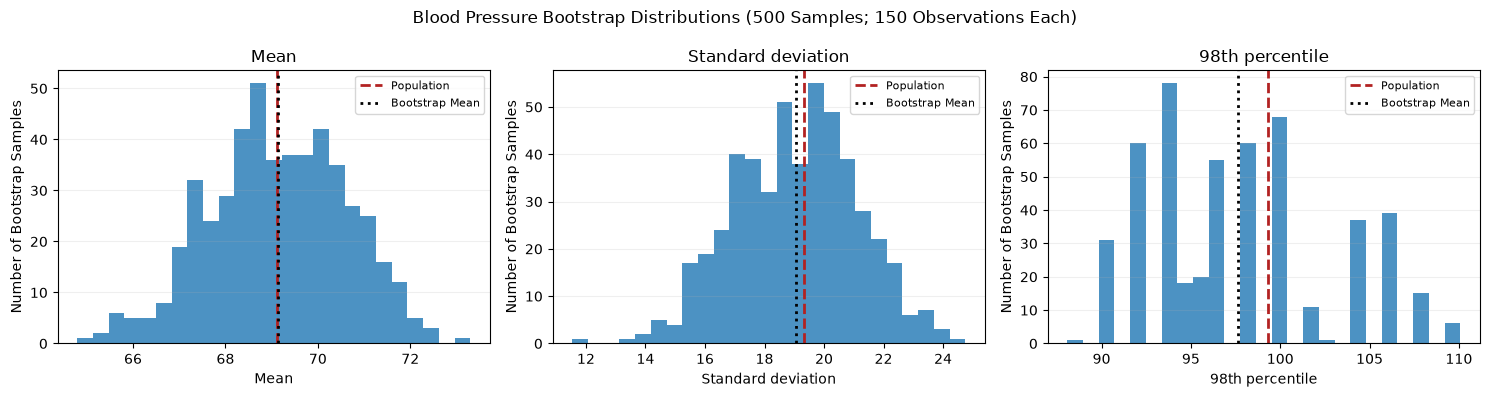

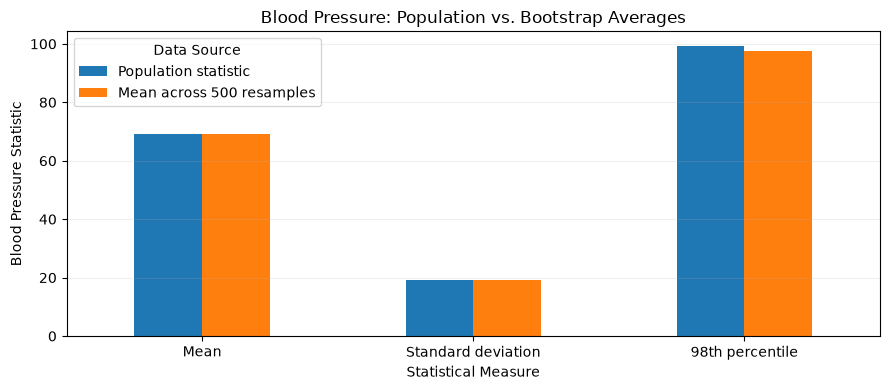


Bootstrap Analysis Findings

Mean:
  Population Statistic: 69.105
  Average Bootstrap Statistic: 69.136
  Difference: +0.031

Standard deviation:
  Population Statistic: 19.343
  Average Bootstrap Statistic: 19.059
  Difference: -0.284

98th percentile:
  Population Statistic: 99.320
  Average Bootstrap Statistic: 97.656
  Difference: -1.664

All bootstrap validation checks passed successfully.


In [14]:
# ============================================================
# 1. Define Bootstrap Sampling Parameters
# ============================================================

# Specify the number of bootstrap samples and the
# number of observations in each sample.
num_bootstrap_samples = 500
bootstrap_sample_size = 150

# Define the percentile to calculate.
percentile_level = 98

# Extract population blood pressure values as a NumPy array.
blood_pressure = population["BloodPressure"].to_numpy()


# ============================================================
# 2. Generate Bootstrap Samples
# ============================================================

# Generate 500 random samples containing 150 observations
# each, sampling with replacement.
#
# Sampling with replacement allows the same population
# observation to appear multiple times in a sample.
bootstrap_indices = rng.integers(
    low=0,
    high=len(blood_pressure),
    size=(num_bootstrap_samples, bootstrap_sample_size)
)

# Retrieve blood pressure measurements for each sample.
bootstrap_bp = blood_pressure[bootstrap_indices]


# ============================================================
# 3. Calculate Statistics for Each Bootstrap Sample
# ============================================================

# Calculate the mean, sample standard deviation, and
# 98th percentile for each of the 500 bootstrap samples.
bootstrap_stats = pd.DataFrame({
    "Mean": bootstrap_bp.mean(axis=1),

    "Standard deviation": bootstrap_bp.std(
        axis=1,
        ddof=1
    ),

    "98th percentile": np.percentile(
        bootstrap_bp,
        percentile_level,
        axis=1
    )
})


# ============================================================
# 4. Calculate Population Blood Pressure Statistics
# ============================================================

# Calculate descriptive statistics for the full population.
#
# Use ddof=0 for the population standard deviation
# because all 768 observations are treated as the population.
population_stats = pd.Series({
    "Mean": blood_pressure.mean(),

    "Standard deviation": blood_pressure.std(
        ddof=0
    ),

    "98th percentile": np.percentile(
        blood_pressure,
        percentile_level
    )
})


# ============================================================
# 5. Compare Bootstrap and Population Statistics
# ============================================================

# Calculate the average value of each statistic
# across all 500 bootstrap samples.
bootstrap_average_stats = bootstrap_stats.mean()

# Create a comparison table.
comparison = pd.DataFrame({
    "Population statistic": population_stats,
    "Mean across 500 resamples": bootstrap_average_stats
})

# Calculate the differences between the average bootstrap
# statistics and the population statistics.
comparison["Bootstrap minus population"] = (
    comparison["Mean across 500 resamples"]
    - comparison["Population statistic"]
)

# Display the statistical comparison.
print("Blood Pressure: Bootstrap vs. Population Statistics")

display(
    comparison.round(3)
)


# ============================================================
# 6. Visualize Bootstrap Sampling Distributions
# ============================================================

# Create three histograms showing the distributions
# of the bootstrap mean, standard deviation, and percentile.
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 4)
)

# Generate a separate histogram for each statistic.
for ax, statistic in zip(
    axes,
    bootstrap_stats.columns
):

    # Plot the bootstrap sampling distribution.
    ax.hist(
        bootstrap_stats[statistic],
        bins=25,
        alpha=0.8
    )

    # Mark the corresponding population statistic.
    ax.axvline(
        population_stats[statistic],
        color="firebrick",
        linestyle="--",
        linewidth=2,
        label="Population"
    )

    # Mark the average statistic across bootstrap samples.
    ax.axvline(
        bootstrap_stats[statistic].mean(),
        color="black",
        linestyle=":",
        linewidth=2,
        label="Bootstrap Mean"
    )

    # Configure chart labels and title.
    ax.set(
        title=statistic,
        xlabel=statistic,
        ylabel="Number of Bootstrap Samples"
    )

    # Add gridlines and a legend.
    ax.grid(
        axis="y",
        alpha=0.2
    )

    ax.legend(
        fontsize=8
    )

# Add an overall title describing the experiment.
fig.suptitle(
    "Blood Pressure Bootstrap Distributions "
    "(500 Samples; 150 Observations Each)",
    fontsize=12
)

# Adjust spacing and display the charts.
plt.tight_layout()
plt.show()


# ============================================================
# 7. Visualize Population and Bootstrap Statistics
# ============================================================

# Create a grouped bar chart comparing the population
# statistics with the average bootstrap statistics.
fig, ax = plt.subplots(
    figsize=(9, 4)
)

comparison[
    [
        "Population statistic",
        "Mean across 500 resamples"
    ]
].plot.bar(
    ax=ax,
    rot=0
)

# Configure the title and axis labels.
ax.set(
    title="Blood Pressure: Population vs. Bootstrap Averages",
    xlabel="Statistical Measure",
    ylabel="Blood Pressure Statistic"
)

# Add horizontal gridlines.
ax.grid(
    axis="y",
    alpha=0.2
)

# Add a legend.
ax.legend(
    title="Data Source"
)

# Adjust spacing and display the chart.
plt.tight_layout()
plt.show()


# ============================================================
# 8. Report Bootstrap Analysis Findings
# ============================================================

# Display the difference between the bootstrap averages
# and the corresponding population statistics.
print("\nBootstrap Analysis Findings")

for statistic in comparison.index:

    population_value = comparison.loc[
        statistic,
        "Population statistic"
    ]

    bootstrap_value = comparison.loc[
        statistic,
        "Mean across 500 resamples"
    ]

    difference = comparison.loc[
        statistic,
        "Bootstrap minus population"
    ]

    print(f"\n{statistic}:")
    print(f"  Population Statistic: {population_value:.3f}")
    print(f"  Average Bootstrap Statistic: {bootstrap_value:.3f}")
    print(f"  Difference: {difference:+.3f}")


# ============================================================
# 9. Validate Bootstrap Sampling Results
# ============================================================

# Confirm that exactly 500 bootstrap samples were created,
# with 150 blood pressure observations in each sample.
assert bootstrap_bp.shape == (
    num_bootstrap_samples,
    bootstrap_sample_size
), (
    "Bootstrap sample dimensions are incorrect."
)

# Confirm that all sampled indices are valid.
assert bootstrap_indices.min() >= 0, (
    "Bootstrap indices contain negative values."
)

assert bootstrap_indices.max() < len(blood_pressure), (
    "Bootstrap indices exceed the population size."
)

# Confirm that all three statistics were calculated
# for each of the 500 bootstrap samples.
assert bootstrap_stats.shape == (
    num_bootstrap_samples,
    3
), (
    "Bootstrap statistics table has incorrect dimensions."
)

# Confirm that the calculated statistics are finite.
assert np.isfinite(bootstrap_stats.to_numpy()).all(), (
    "Invalid values detected in bootstrap statistics."
)

# Confirm that the comparison table contains three statistics.
assert len(comparison) == 3, (
    "The population comparison table is incomplete."
)

print("\nAll bootstrap validation checks passed successfully.")


## Findings and interpretation

The printed values below summarize the **actual executed** calculations rather than supplying expected or invented results. In 500 resamples, the bootstrap average of the mean should generally be near the population mean, but each finite simulation varies. The standard deviation may differ slightly because it averages sample standard deviations (`ddof=1`) while the reference is the defined population standard deviation (`ddof=0`). An extreme 98th percentile may be noticeably less stable than the mean, especially with only 150 observations per resample. The supplied dataset contains zero BloodPressure records; zeros are not silently removed or replaced. No causal or clinical conclusions follow from these comparisons.

In [15]:
# ============================================================
# 1. Report Observed Bootstrap Findings
# ============================================================

# Display the population statistics, average bootstrap
# statistics, and differences for each statistical measure.
print("OBSERVED BOOTSTRAP FINDINGS")
print("-" * 60)

for statistic in comparison.index:

    # Retrieve the results for the current statistic.
    results = comparison.loc[statistic]

    population_value = results[
        "Population statistic"
    ]

    bootstrap_mean = results[
        "Mean across 500 resamples"
    ]

    difference = results[
        "Bootstrap minus population"
    ]

    # Display the statistical comparison.
    print(f"\n{statistic}:")

    print(f"  Population Statistic: {population_value:.3f}")

    print(f"  Average Bootstrap Statistic: {bootstrap_mean:.3f}")

    print(f"  Difference: {difference:+.3f}")


# ============================================================
# 2. Identify Potential Data Quality Limitations
# ============================================================

# Count observations with a BloodPressure value of zero.
# These values may represent missing measurements
# rather than clinically meaningful blood pressure values.
zero_blood_pressure_count = int(
    (population["BloodPressure"] == 0).sum()
)

print("\nDATA QUALITY OBSERVATIONS")
print("-" * 60)

print(
    f"Zero BloodPressure Entries Included: "
    f"{zero_blood_pressure_count}"
)

print(
    "All bootstrap samples were drawn with replacement."
)

print(
    "The original dataset was treated as the complete "
    "population, as specified in the assignment."
)


# ============================================================
# 3. Define the Results Output Directory
# ============================================================

# Specify the directory for storing statistical
# comparison tables and bootstrap results.
results_directory = ROOT / "results"

# Create the directory if it does not already exist.
results_directory.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 4. Export Blood Pressure Bootstrap Results
# ============================================================

# Save the population and bootstrap comparison table.
# Round values to six decimal places for readable output.
bootstrap_comparison_path = (
    results_directory /
    "blood_pressure_bootstrap_comparison.csv"
)

comparison.round(6).to_csv(
    bootstrap_comparison_path
)

# Save the individual statistics calculated
# for all 500 bootstrap samples.
bootstrap_statistics_path = (
    results_directory /
    "blood_pressure_bootstrap_statistics.csv"
)

bootstrap_stats.to_csv(
    bootstrap_statistics_path,
    index=False
)


# ============================================================
# 5. Export Glucose and BMI Comparison Results
# ============================================================

# Save the sample and population glucose statistics.
glucose_results_path = (
    results_directory /
    "glucose_comparison.csv"
)

glucose_metrics.to_csv(
    glucose_results_path,
    index=False
)

# Save the sample and population BMI percentile results.
bmi_results_path = (
    results_directory /
    "bmi_comparison.csv"
)

bmi_comparison.to_csv(
    bmi_results_path,
    index=False
)


# ============================================================
# 6. Validate Exported Results
# ============================================================

# Collect the expected output files.
exported_files = [
    bootstrap_comparison_path,
    bootstrap_statistics_path,
    glucose_results_path,
    bmi_results_path
]

# Confirm that all required result files were created.
for file_path in exported_files:

    assert file_path.is_file(), (
        f"Expected result file was not created: {file_path}"
    )

# Confirm that the bootstrap statistics contain
# exactly 500 observations.
assert len(bootstrap_stats) == 500, (
    "The bootstrap results do not contain 500 samples."
)

# Confirm that the comparison table includes
# the three required statistical measures.
required_statistics = [
    "Mean",
    "Standard deviation",
    "98th percentile"
]

assert all(
    statistic in comparison.index
    for statistic in required_statistics
), (
    "One or more required bootstrap statistics are missing."
)


# ============================================================
# 7. Display Export Summary
# ============================================================

print("\nRESULTS EXPORT SUMMARY")
print("-" * 60)

print("All statistical results exported successfully.\n")

for file_path in exported_files:

    print(
        f"Saved: {file_path.relative_to(ROOT)}"
    )

print("\nAll result file validation checks passed.")


OBSERVED BOOTSTRAP FINDINGS
------------------------------------------------------------

Mean:
  Population Statistic: 69.105
  Average Bootstrap Statistic: 69.136
  Difference: +0.031

Standard deviation:
  Population Statistic: 19.343
  Average Bootstrap Statistic: 19.059
  Difference: -0.284

98th percentile:
  Population Statistic: 99.320
  Average Bootstrap Statistic: 97.656
  Difference: -1.664

DATA QUALITY OBSERVATIONS
------------------------------------------------------------
Zero BloodPressure Entries Included: 35
All bootstrap samples were drawn with replacement.
The original dataset was treated as the complete population, as specified in the assignment.

RESULTS EXPORT SUMMARY
------------------------------------------------------------
All statistical results exported successfully.

Saved: results/blood_pressure_bootstrap_comparison.csv
Saved: results/blood_pressure_bootstrap_statistics.csv
Saved: results/glucose_comparison.csv
Saved: results/bmi_comparison.csv

All res